Cell 1: Imports & Model Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
import chromadb

# Load embedding model
model_name = "all-MiniLM-L6-v2"
print(f" Loading SentenceTransformer model '{model_name}'...")
model = SentenceTransformer(model_name)
print(" Model loaded successfully!")

 Loading SentenceTransformer model 'all-MiniLM-L6-v2'...
 Model loaded successfully!


Cell 2: What does a Vector Embedding look like? (Deep Inspection)

In [3]:
# Sample text from our dataset
sample_text = "Title: Dune | Author: Frank Herbert | Genre: Sci-Fi & Dystopian | Summary: Desert planet Arrakis spice war"

# Convert text into numerical vector
embedding_vector = model.encode(sample_text)

print(f" Input Text: '{sample_text}'\n")
print(f" Vector Dimensions (Shape): {embedding_vector.shape} (List of 384 floating point numbers)")
print(f" First 15 Numbers of the Vector Embedding:\n{embedding_vector[:15]}\n")
print(f" Vector Min: {embedding_vector.min():.4f} | Max: {embedding_vector.max():.4f} | Mean: {embedding_vector.mean():.4f}")


 Input Text: 'Title: Dune | Author: Frank Herbert | Genre: Sci-Fi & Dystopian | Summary: Desert planet Arrakis spice war'

 Vector Dimensions (Shape): (384,) (List of 384 floating point numbers)
 First 15 Numbers of the Vector Embedding:
[ 0.00536939 -0.01040901 -0.09684817  0.02751587  0.02563892  0.05189687
 -0.0321074  -0.03934693  0.06143095  0.01394941  0.0661471  -0.0041355
  0.04945033 -0.05846445  0.00356031]

 Vector Min: -0.1500 | Max: 0.1551 | Mean: -0.0003


Cell 3: Vector Math Demo (Cosine Similarity in Action)

In [4]:
# Let's test 3 sentences to see how vector space understands semantic meanings
sentence1 = "Interstellar space journey to distant galaxies"
sentence2 = "Astronaut mission exploring deep cosmos and alien worlds"
sentence3 = "Baking a delicious sweet chocolate cake recipe"

# Generate embeddings
vec1 = model.encode(sentence1)
vec2 = model.encode(sentence2)
vec3 = model.encode(sentence3)

# Manual Cosine Similarity Formula: (A . B) / (||A|| * ||B||)
def cosine_sim(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

sim1_2 = cosine_sim(vec1, vec2)
sim1_3 = cosine_sim(vec1, vec3)

print(" SEMANTIC VECTOR SIMILARITY DEMO:\n")
print(f"Sentence 1: '{sentence1}'")
print(f"Sentence 2: '{sentence2}'")
print(f"Sentence 3: '{sentence3}'\n")

print(f" Similarity (Sentence 1 vs Sentence 2 - Both Sci-Fi): {sim1_2:.4f} (High Similarity! 🎯)")
print(f" Similarity (Sentence 1 vs Sentence 3 - Sci-Fi vs Food): {sim1_3:.4f} (Low Similarity! ❌)")


 SEMANTIC VECTOR SIMILARITY DEMO:

Sentence 1: 'Interstellar space journey to distant galaxies'
Sentence 2: 'Astronaut mission exploring deep cosmos and alien worlds'
Sentence 3: 'Baking a delicious sweet chocolate cake recipe'

 Similarity (Sentence 1 vs Sentence 2 - Both Sci-Fi): 0.5330 (High Similarity! 🎯)
 Similarity (Sentence 1 vs Sentence 3 - Sci-Fi vs Food): 0.0989 (Low Similarity! ❌)


Cell 4: Visualizing Vector Clusters in 2D (PCA Scatter Plot)

 Generating embeddings for 150 multi-genre books for 2D visualization...


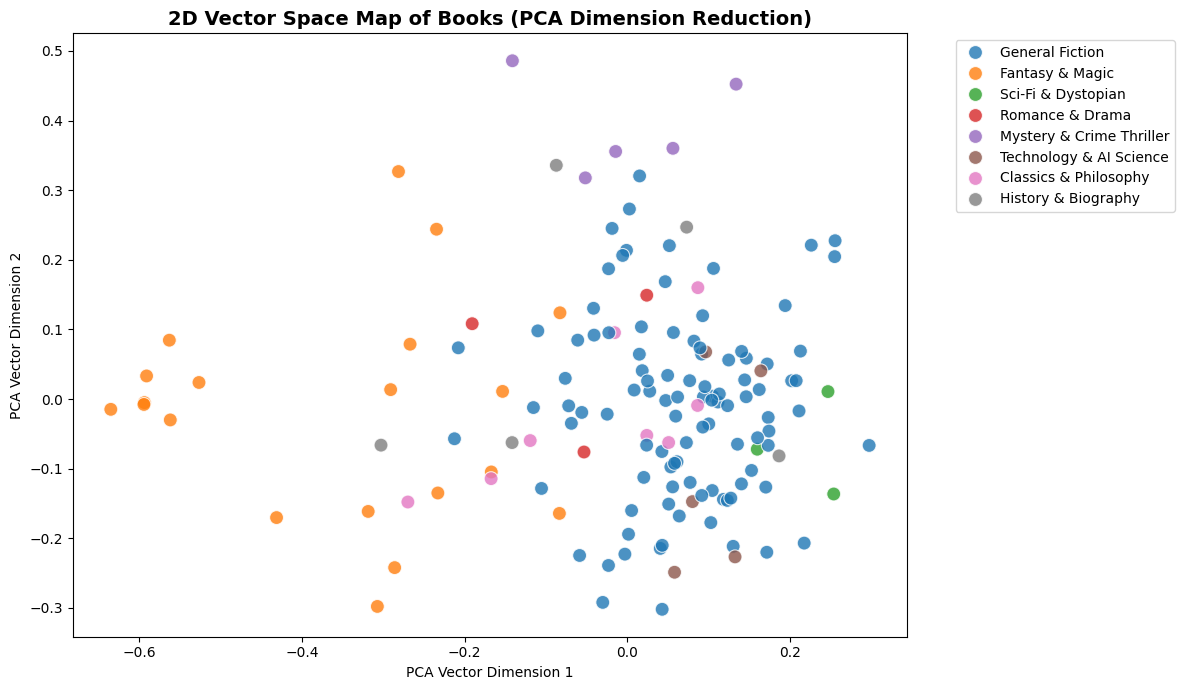

In [5]:
# Load clean books dataset
df = pd.read_csv("../data/books_cleaned.csv").head(150) # Sample 150 books

print(" Generating embeddings for 150 multi-genre books for 2D visualization...")
sample_vectors = model.encode(df['combined_text'].tolist())

# Reduce 384 dimensions to 2D using PCA (Principal Component Analysis)
pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(sample_vectors)

# Add 2D coordinates to DataFrame
df['pca_x'] = vectors_2d[:, 0]
df['pca_y'] = vectors_2d[:, 1]

# Plot Scatter Chart
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df, x='pca_x', y='pca_y', hue='genres', 
    palette='tab10', s=100, alpha=0.8
)

plt.title("2D Vector Space Map of Books (PCA Dimension Reduction)", fontsize=14, fontweight='bold')
plt.xlabel("PCA Vector Dimension 1")
plt.ylabel("PCA Vector Dimension 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


Cell 5: Interactive Search Table using ChromaDB

In [6]:
# Initialize ChromaDB persistent client
client = chromadb.PersistentClient(path="../data/chroma_db")
collection = client.get_collection(name="shelfknows_books")

def search_books_interactive(user_query, top_k=5):
    results = collection.query(query_texts=[user_query], n_results=top_k)
    metas = results['metadatas'][0]
    distances = results['distances'][0]
    
    results_df = pd.DataFrame(metas)
    results_df['similarity_score'] = [round(max(0, 1 - d), 4) for d in distances]
    
    print(f"🔍 Query: '{user_query}'")
    return results_df[['title', 'authors', 'genres', 'average_rating', 'similarity_score']]

# Test interactive cell:
search_books_interactive("dark magic and wizardry adventure", top_k=5)


Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
/Users/simranchaudhary/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:32<00:00, 2.53MiB/s]  
Failed to send telemetry event CollectionQueryEvent: capture() takes 1 positional argument but 3 were given


🔍 Query: 'dark magic and wizardry adventure'


,title,authors,genres,average_rating,similarity_score
0,"Dark Magic (Dark, #4)",Christine Feehan,Fantasy & Magic,4.24,0.5610
1,"A Darker Shade of Magic (Shades of Magic, #1)","V.E. Schwab, Victoria Schwab",Fantasy & Magic,4.07,0.5509
2,"A Gathering of Shadows (Shades of Magic, #2)","V.E. Schwab, Victoria Schwab",Fantasy & Magic,4.33,0.5136
3,"Gathering Darkness (Falling Kingdoms, #3)","Morgan Rhodes, Michelle Rowen",Fantasy & Magic,4.33,0.5020
4,The Magical Worlds of Harry Potter: A Treasury...,David Colbert,Fantasy & Magic,3.96,0.5016
